In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import os
from sqlalchemy import create_engine

In [3]:
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110

In [4]:
OUT_DIR = "charts"
os.makedirs(OUT_DIR, exist_ok=True)

In [5]:
# My SQL Connection

In [6]:
DB_CONFIG = {
    "host": "127.0.0.1",
    "port": 3306,
    "user": "root",            # <-- your MySQL username
    "password": "0812",  # <-- your MySQL password
    "database": "Zomato_sales",
}

In [7]:
engine = create_engine(
    f"mysql+pymysql://{DB_CONFIG['user']}:{DB_CONFIG['password']}"
    f"@{DB_CONFIG['host']}:{DB_CONFIG['port']}/{DB_CONFIG['database']}"
)

In [8]:
# Loading Tables with Pandas, Straight from my MYSQL

In [9]:
restaurants = pd.read_sql("SELECT * FROM restaurants", engine)
customers = pd.read_sql("SELECT * FROM customers", engine)
orders = pd.read_sql("SELECT * FROM orders", engine, parse_dates=["order_date"])
order_items = pd.read_sql("SELECT * FROM order_items", engine)

In [10]:
# Feature Engineering

In [11]:
orders["month"] = orders["order_date"].dt.to_period("M").astype(str)
orders["day_of_week"] = orders["order_date"].dt.day_name()
orders["year"] = orders["order_date"].dt.year

In [12]:
orders_full = orders.merge(restaurants, on="restaurant_id", suffixes=("", "_rest"))

In [13]:
# 1. Monthly revenue trend (with 3-month rolling average)

In [14]:
monthly = orders.groupby("month").agg(
    orders=("order_id", "count"),
    revenue=("total_amount", "sum")
).reset_index()
monthly["revenue_3mo_avg"] = monthly["revenue"].rolling(3).mean()

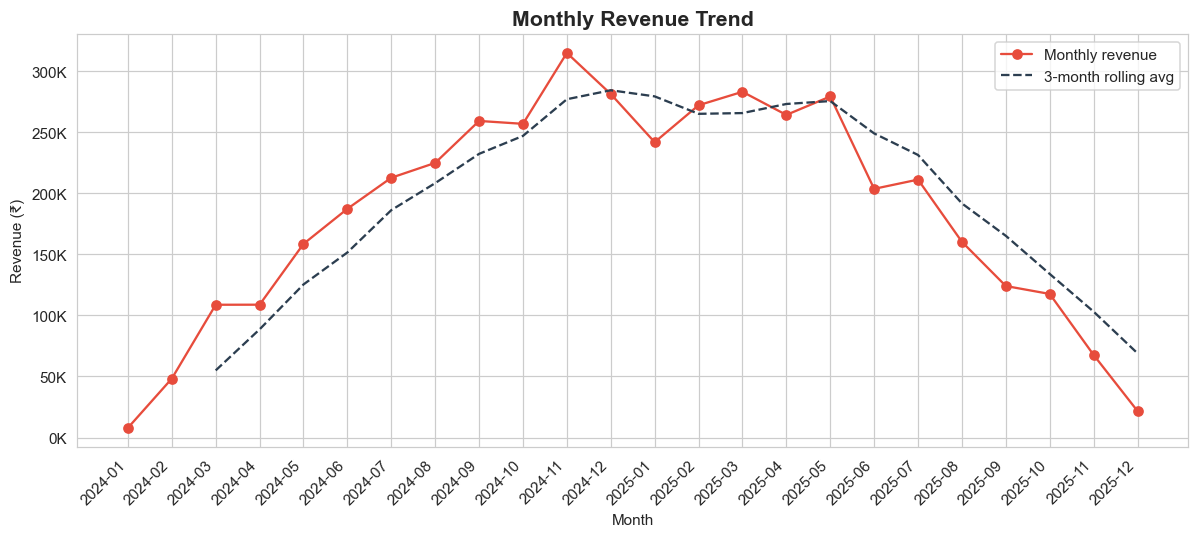

In [15]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(monthly["month"], monthly["revenue"], marker="o", label="Monthly revenue", color="#e74c3c")
ax.plot(monthly["month"], monthly["revenue_3mo_avg"], linestyle="--", label="3-month rolling avg", color="#2c3e50")
ax.set_title("Monthly Revenue Trend", fontsize=14, fontweight="bold")
ax.set_ylabel("Revenue (₹)")
ax.set_xlabel("Month")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x/1000:.0f}K"))
plt.xticks(rotation=45, ha="right")
ax.legend()
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/01_monthly_revenue_trend.png")
plt.show()
plt.close()

In [16]:
# 2. Revenue by cuisine (top 10)

In [17]:
cuisine_rev = orders_full.groupby("cuisine")["total_amount"].sum().sort_values(ascending=False).head(10)

C:\Users\Toxic74\AppData\Local\Temp\ipykernel_14928\411493152.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cuisine_rev.values, y=cuisine_rev.index, ax=ax, palette="rocket")


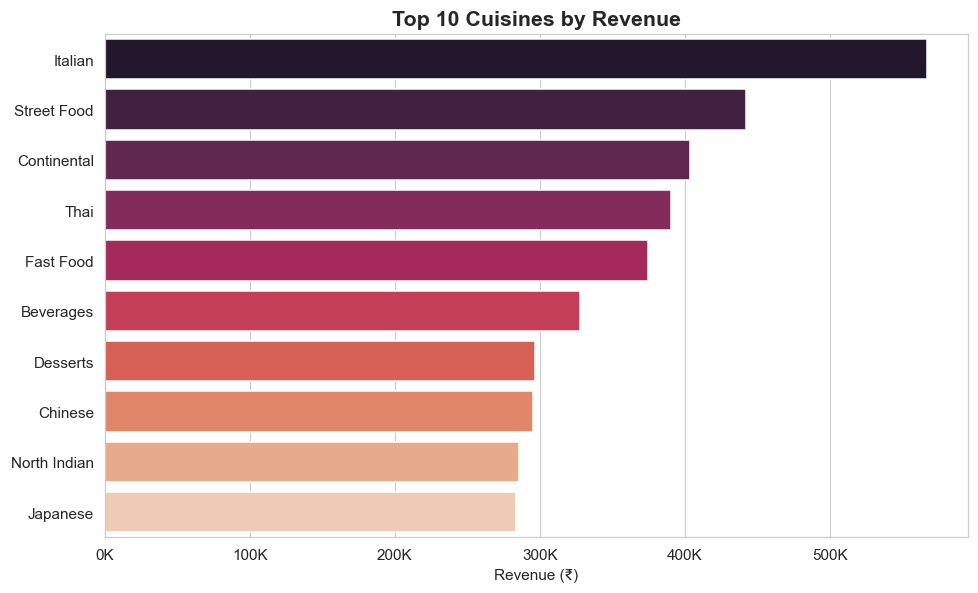

In [18]:
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.barplot(x=cuisine_rev.values, y=cuisine_rev.index, ax=ax, palette="rocket")
ax.set_title("Top 10 Cuisines by Revenue", fontsize=14, fontweight="bold")
ax.set_xlabel("Revenue (₹)")
ax.set_ylabel("")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x/1000:.0f}K"))
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/02_revenue_by_cuisine.png")
plt.show()
plt.close()

In [19]:
# 3. City-wise revenue

In [23]:
city_rev = orders_full.groupby("city")["total_amount"].sum().sort_values(ascending=False)

C:\Users\Toxic74\AppData\Local\Temp\ipykernel_14928\1861302940.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=city_rev.index, y=city_rev.values, ax=ax, palette="mako")


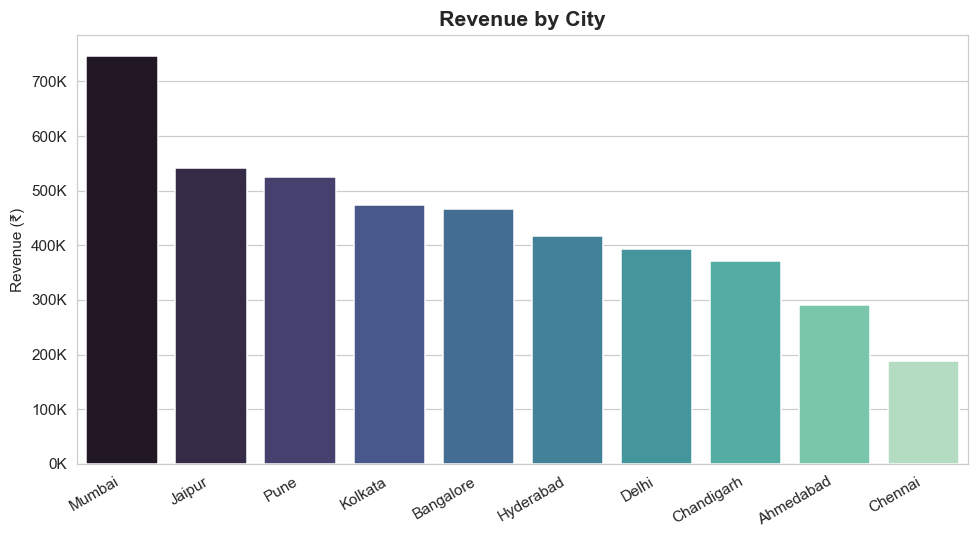

In [24]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(x=city_rev.index, y=city_rev.values, ax=ax, palette="mako")
ax.set_title("Revenue by City", fontsize=14, fontweight="bold")
ax.set_ylabel("Revenue (₹)")
ax.set_xlabel("")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x/1000:.0f}K"))
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/03_revenue_by_city.png")
plt.show()
plt.close()

In [25]:
# 4. Order volume by day of week (with weekend highlight)

In [26]:
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
dow = orders.groupby("day_of_week")["order_id"].count().reindex(day_order)
colors = ["#95a5a6"] * 5 + ["#e67e22", "#e67e22"]

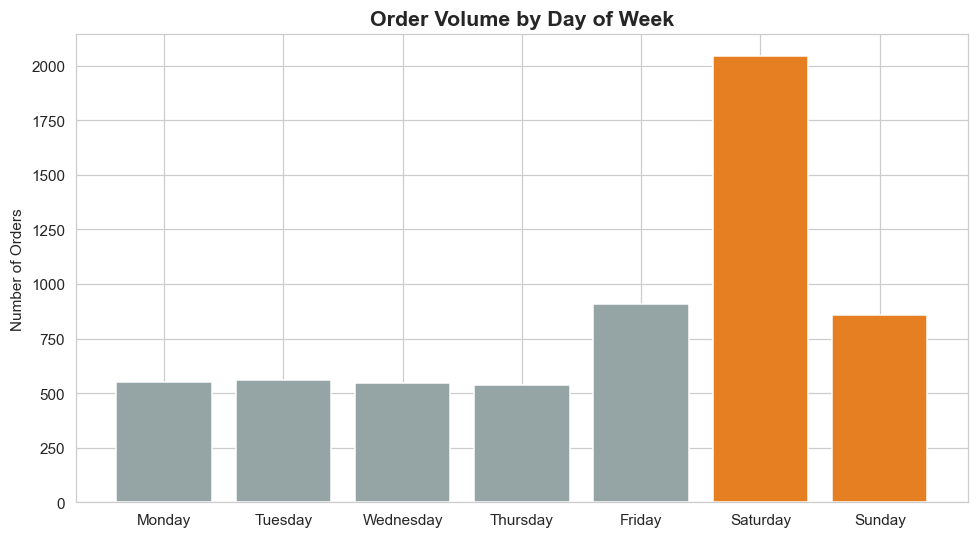

In [27]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(dow.index, dow.values, color=colors)
ax.set_title("Order Volume by Day of Week", fontsize=14, fontweight="bold")
ax.set_ylabel("Number of Orders")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/04_orders_by_day_of_week.png")
plt.show()
plt.close()

In [58]:
# 5. Payment method distribution (pie)

In [28]:
pay = orders["payment_method"].value_counts()

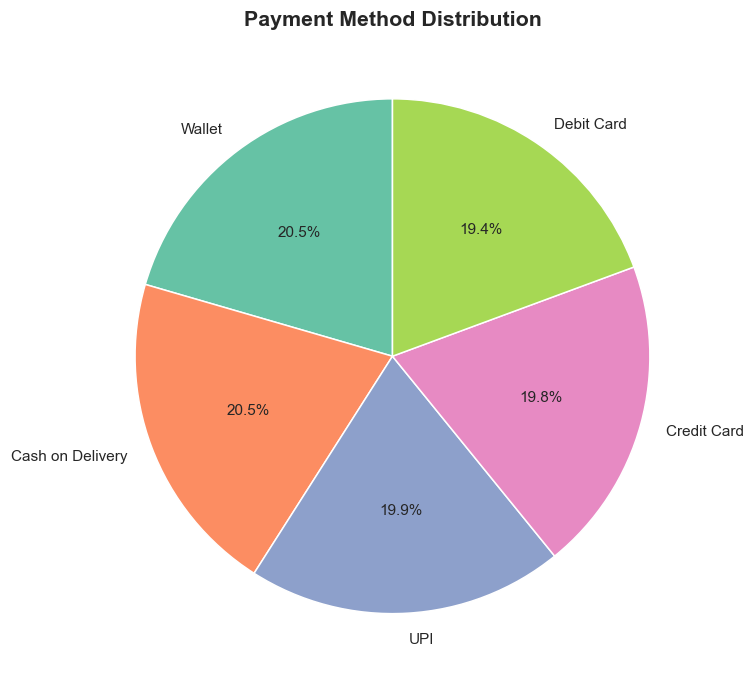

In [30]:
fig, ax = plt.subplots(figsize=(7, 7))
ax.pie(pay.values, labels=pay.index, autopct="%1.1f%%", startangle=90,
       colors=sns.color_palette("Set2", len(pay)))
ax.set_title("Payment Method Distribution", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/05_payment_method_distribution.png")
plt.show()
plt.close()

In [61]:
# 6. Best-selling items (top 10 by revenue)

In [62]:
item_rev = order_items.groupby("item_name")["line_total"].sum().sort_values(ascending=False).head(10)

C:\Users\Toxic74\AppData\Local\Temp\ipykernel_5040\4192062740.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=item_rev.values, y=item_rev.index, ax=ax, palette="flare")


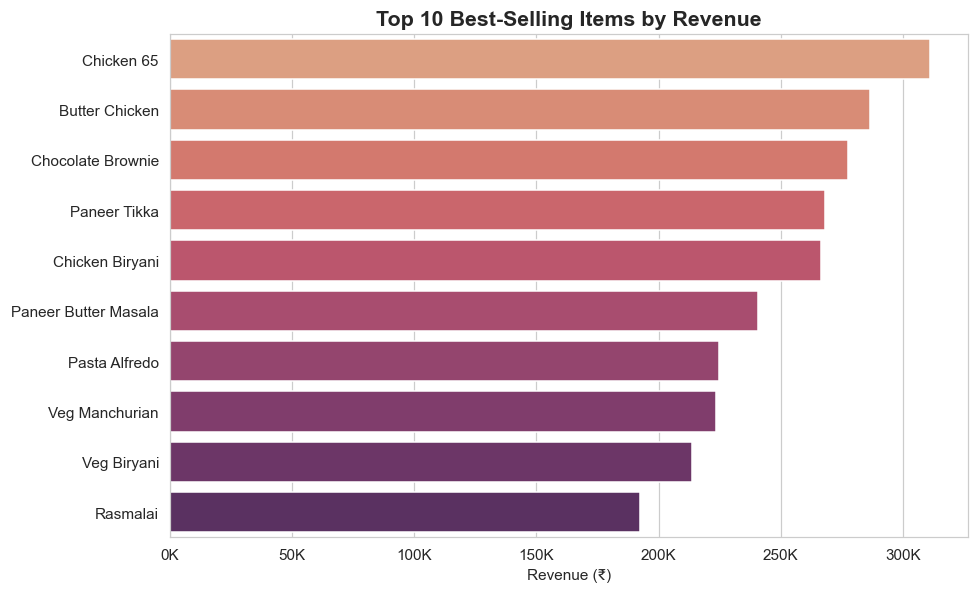

In [107]:
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.barplot(x=item_rev.values, y=item_rev.index, ax=ax, palette="flare")
ax.set_title("Top 10 Best-Selling Items by Revenue", fontsize=14, fontweight="bold")
ax.set_xlabel("Revenue (₹)")
ax.set_ylabel("")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x/1000:.0f}K"))
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/06_top_items_by_revenue.png")
plt.show()
plt.close()

In [64]:
# 7. Discount % vs Average Order Value

In [65]:
disc = orders.groupby("discount_pct")["total_amount"].mean()

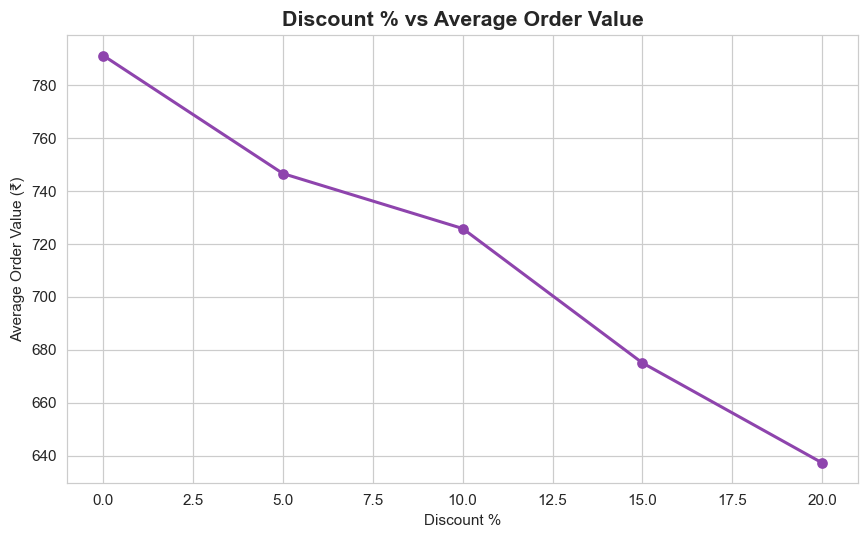

In [108]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(disc.index, disc.values, marker="o", color="#8e44ad", linewidth=2)
ax.set_title("Discount % vs Average Order Value", fontsize=14, fontweight="bold")
ax.set_xlabel("Discount %")
ax.set_ylabel("Average Order Value (₹)")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/07_discount_vs_aov.png")
plt.show()
plt.close()

In [67]:
# 8. Customer rating distribution

In [68]:
ratings = orders["customer_rating"].dropna()

C:\Users\Toxic74\AppData\Local\Temp\ipykernel_5040\1808252914.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=ratings.astype(int), ax=ax, palette="crest", order=[1, 2, 3, 4, 5])


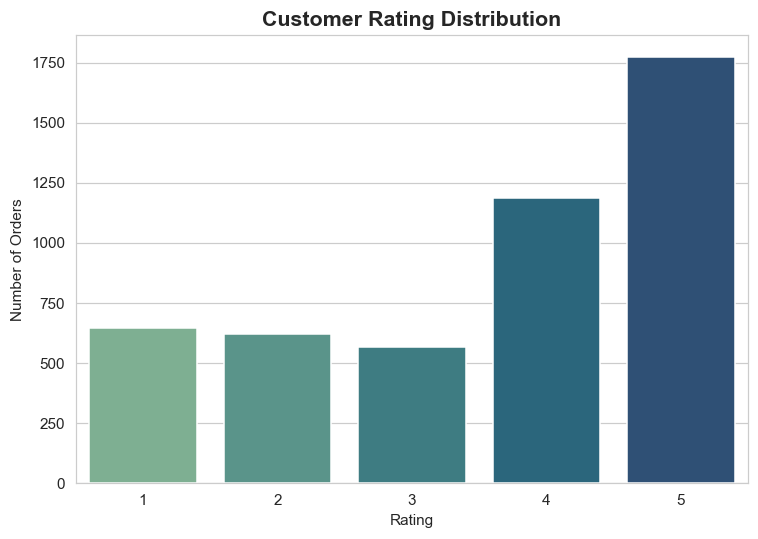

In [109]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.countplot(x=ratings.astype(int), ax=ax, palette="crest", order=[1, 2, 3, 4, 5])
ax.set_title("Customer Rating Distribution", fontsize=14, fontweight="bold")
ax.set_xlabel("Rating")
ax.set_ylabel("Number of Orders")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/08_rating_distribution.png")
plt.show()
plt.close()

In [94]:
# 9. Restaurant rating vs revenue (scatter)

In [95]:
rest_perf = orders_full.groupby(["restaurant_id", "restaurant_name", "rating"]).agg(
    revenue=("total_amount", "sum"),
    num_orders=("order_id", "count")
).reset_index()

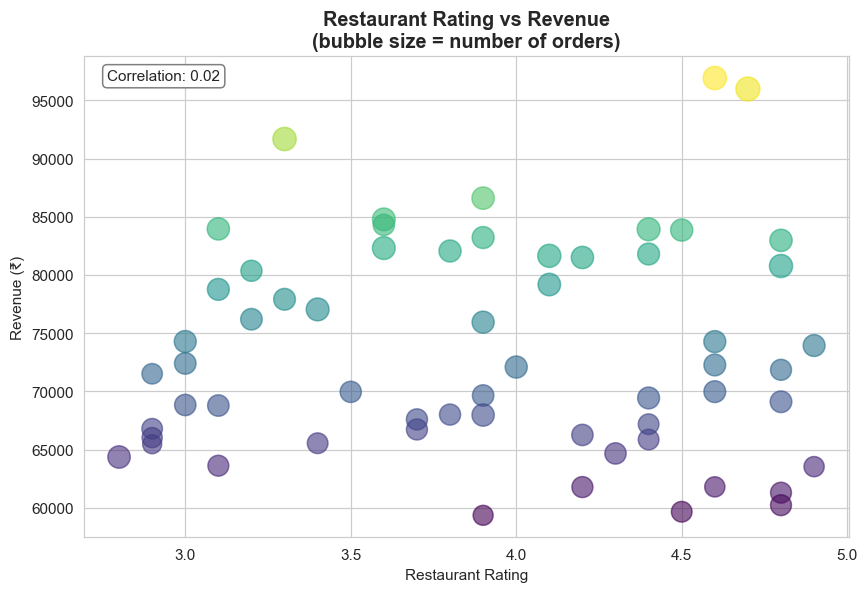

In [110]:
fig, ax = plt.subplots(figsize=(8, 5.5))
sc = ax.scatter(rest_perf["rating"], rest_perf["revenue"], s=rest_perf["num_orders"] * 2,
                 alpha=0.6, c=rest_perf["revenue"], cmap="viridis")
ax.set_title("Restaurant Rating vs Revenue\n(bubble size = number of orders)", fontsize=13, fontweight="bold")
ax.set_xlabel("Restaurant Rating")
ax.set_ylabel("Revenue (₹)")
corr = rest_perf["rating"].corr(rest_perf["revenue"])
ax.annotate(f"Correlation: {corr:.2f}", xy=(0.03, 0.95), xycoords="axes fraction", fontsize=10,
            bbox=dict(boxstyle="round", fc="white", ec="gray"))
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/09_rating_vs_revenue.png")
plt.show()
plt.close()

In [70]:
# 10. Customer spend distribution

In [71]:
cust_spend = orders.groupby("customer_id")["total_amount"].sum()

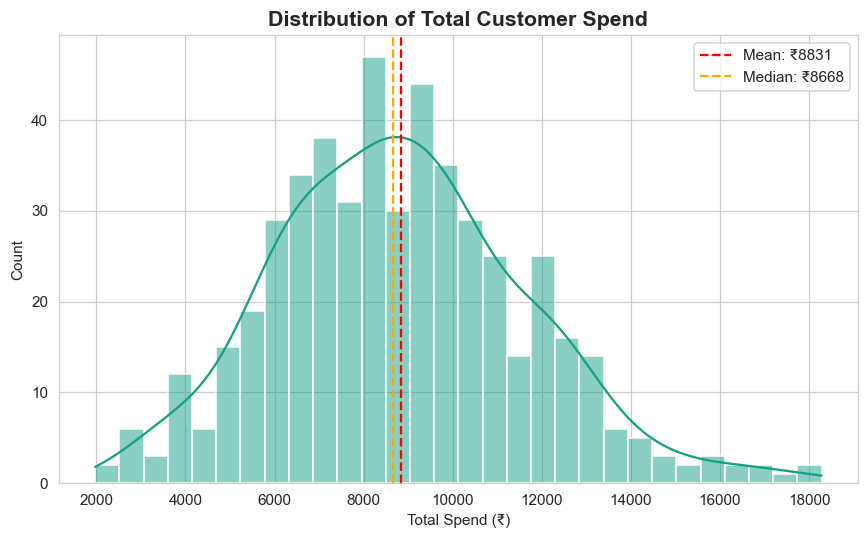

In [111]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(cust_spend, bins=30, kde=True, color="#16a085", ax=ax)
ax.axvline(cust_spend.mean(), color="red", linestyle="--", label=f"Mean: ₹{cust_spend.mean():.0f}")
ax.axvline(cust_spend.median(), color="orange", linestyle="--", label=f"Median: ₹{cust_spend.median():.0f}")
ax.set_title("Distribution of Total Customer Spend", fontsize=14, fontweight="bold")
ax.set_xlabel("Total Spend (₹)")
ax.legend()
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/10_customer_spend_distribution.png")
plt.show()
plt.close()

In [73]:
# Key statistical insights

In [112]:
print(f"\n1. Correlation between restaurant rating and revenue: {corr:.3f}")


1. Correlation between restaurant rating and revenue: 0.025


In [115]:
best_month = monthly.loc[monthly["revenue"].idxmax()]
print(f"\n2. Best month: {best_month['month']} with revenue ₹{best_month['revenue']:,.0f}")


2. Best month: 2024-11 with revenue ₹314,938


In [116]:
weekend_share = dow[["Saturday", "Sunday"]].sum() / dow.sum() * 100
print(f"\n3. Weekend orders make up {weekend_share:.1f}% of all orders (2/7 days = 28.6% if uniform)")


3. Weekend orders make up 48.3% of all orders (2/7 days = 28.6% if uniform)


In [117]:
top_spender_share = cust_spend.sort_values(ascending=False).head(50).sum() / cust_spend.sum() * 100
print(f"\n4. Top 50 customers (10% of customer base) account for {top_spender_share:.1f}% of total revenue")


4. Top 50 customers (10% of customer base) account for 16.0% of total revenue


In [118]:
disc_corr = orders["discount_pct"].corr(orders["total_amount"])
print(f"\n5. Correlation between discount % and order value: {disc_corr:.3f}")
print("   (negative = bigger discounts tend to come with smaller orders)")


5. Correlation between discount % and order value: -0.121
   (negative = bigger discounts tend to come with smaller orders)
